In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [70]:
df = pd.read_csv("DataSets/FantasyData.csv")
min_attempts = 15
attempt_columns = ['Tgt', 'RushAtt', 'PassAtt']
row_count_before_filter = len(df)
df = df.loc[df[attempt_columns].fillna(0).ge(min_attempts).any(axis=1)].copy()
print(f"Filtered out {row_count_before_filter - len(df)} low-usage rows; {len(df)} rows remain.")
df.head()

Filtered out 416 low-usage rows; 767 rows remain.


,Player,year,Age,Team,Pos,G,GS,RushAtt,RushYds,RushTD,...,ReceiveTD,Receive1D,ReceiveLng,ReceiveR/G,ReceiveY/G,Ctch%,Y/Tgt,ReceiveFmb,FantasyPointsPPR,FantasyPPRPerGame
0,A.J. Brown,2024,27.0,PHI,WR,13.0,13.0,0.0,0.0,0.0,...,7.0,63.0,67.0,5.2,83.0,69.1,11.1,0.0,216.90,16.68
1,AJ Barner,2024,22.0,SEA,TE,17.0,6.0,0.0,0.0,0.0,...,4.0,18.0,20.0,1.8,14.4,78.9,6.4,0.0,78.50,4.62
3,Aaron Jones,2024,30.0,MIN,RB,17.0,17.0,255.0,1138.0,5.0,...,2.0,20.0,25.0,3.0,24.0,82.3,6.6,5.0,247.60,14.56
4,Aaron Rodgers,2024,41.0,NYJ,QB,17.0,17.0,22.0,107.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,256.58,15.09
6,Adam Thielen,2024,34.0,CAR,WR,10.0,10.0,0.0,0.0,0.0,...,5.0,28.0,40.0,4.8,61.5,77.4,9.9,0.0,139.50,13.95


In [60]:
df.groupby('Pos')["FantasyPointsPPR"].mean()

Pos
FB        58.300000
QB       139.286260
RB       115.191707
TE        93.427482
WR       115.414325
WR/CB     63.800000
Name: FantasyPointsPPR, dtype: float64

In [61]:
df.groupby('Age')["FantasyPointsPPR"].mean()

Age
20.0     85.200000
21.0     88.411765
22.0    119.618000
23.0    124.591392
24.0    113.140816
25.0    112.300000
26.0    114.240833
27.0    122.213231
28.0    117.163509
29.0    124.823265
30.0    114.872500
31.0    102.744000
32.0     94.920000
33.0     87.942857
34.0    148.048000
35.0     99.190000
36.0    166.468000
37.0    142.680000
38.0     13.520000
39.0     66.710000
40.0    148.660000
41.0    256.580000
42.0    227.080000
44.0     31.660000
Name: FantasyPointsPPR, dtype: float64

In [62]:
df.groupby(["Pos","Age"])["FantasyPointsPPR"].mean()

Pos    Age 
FB     33.0     59.600000
       34.0     57.000000
QB     22.0    151.328000
       23.0    194.394286
       24.0    136.095000
                  ...    
WR     32.0    106.964286
       33.0    134.925000
       34.0    139.500000
       35.0     37.600000
WR/CB  22.0     63.800000
Name: FantasyPointsPPR, Length: 70, dtype: float64

In [47]:
import seaborn as sns

In [48]:
%pip install seaborn


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [64]:
columns_to_keep = ['RushY/A', 'PassTD%', 'Int%', 'Sk%', 'ReceiveY/R', 'Ctch%', 'Y/Tgt', 'G', 'year', 'Age']
dropped = df.drop(columns=df.columns.difference(columns_to_keep))
print(dropped.shape)
dropped.head(20)

(767, 10)


,year,Age,G,RushY/A,PassTD%,Int%,Sk%,ReceiveY/R,Ctch%,Y/Tgt
0,2024,27.0,13.0,0.0,0.0,0.0,0.00,16.1,69.1,11.1
1,2024,22.0,17.0,0.0,0.0,0.0,0.00,8.2,78.9,6.4
3,2024,30.0,17.0,4.5,0.0,0.0,0.00,8.0,82.3,6.6
4,2024,41.0,17.0,4.9,4.8,1.9,6.41,0.0,0.0,0.0
6,2024,34.0,10.0,0.0,0.0,0.0,0.00,12.8,77.4,9.9
7,2024,27.0,17.0,0.0,0.0,0.0,0.00,14.5,59.1,8.5
8,2024,22.0,17.0,1.5,0.0,0.0,0.00,13.6,41.8,5.7
9,2024,26.0,9.0,1.4,3.3,1.6,3.95,0.0,0.0,0.0
12,2024,24.0,16.0,0.0,0.0,0.0,0.00,22.3,53.6,11.9
14,2024,26.0,14.0,3.2,0.0,0.0,0.00,8.2,75.0,6.1


In [65]:
dropped.corr(numeric_only=True)

,year,Age,G,RushY/A,PassTD%,Int%,Sk%,ReceiveY/R,Ctch%,Y/Tgt
year,1.000000,0.025546,-0.060497,-0.021880,-0.017415,0.018727,-0.028798,0.000193,-0.002353,-0.022745
Age,0.025546,1.000000,-0.138003,-0.118722,0.071357,0.103503,0.090505,-0.203923,-0.228510,-0.212578
G,-0.060497,-0.138003,1.000000,-0.001352,0.005155,-0.037395,-0.093037,0.335301,0.377865,0.351621
RushY/A,-0.021880,-0.118722,-0.001352,1.000000,0.040536,-0.045443,0.079632,-0.217507,-0.075492,-0.184835
PassTD%,-0.017415,0.071357,0.005155,0.040536,1.000000,0.004159,0.121625,-0.091211,-0.084569,-0.073046
Int%,0.018727,0.103503,-0.037395,-0.045443,0.004159,1.000000,0.018999,-0.068407,-0.100906,-0.077900
Sk%,-0.028798,0.090505,-0.093037,0.079632,0.121625,0.018999,1.000000,-0.171841,-0.202393,-0.178419
ReceiveY/R,0.000193,-0.203923,0.335301,-0.217507,-0.091211,-0.068407,-0.171841,1.000000,0.521375,0.925483
Ctch%,-0.002353,-0.228510,0.377865,-0.075492,-0.084569,-0.100906,-0.202393,0.521375,1.000000,0.676294
Y/Tgt,-0.022745,-0.212578,0.351621,-0.184835,-0.073046,-0.077900,-0.178419,0.925483,0.676294,1.000000


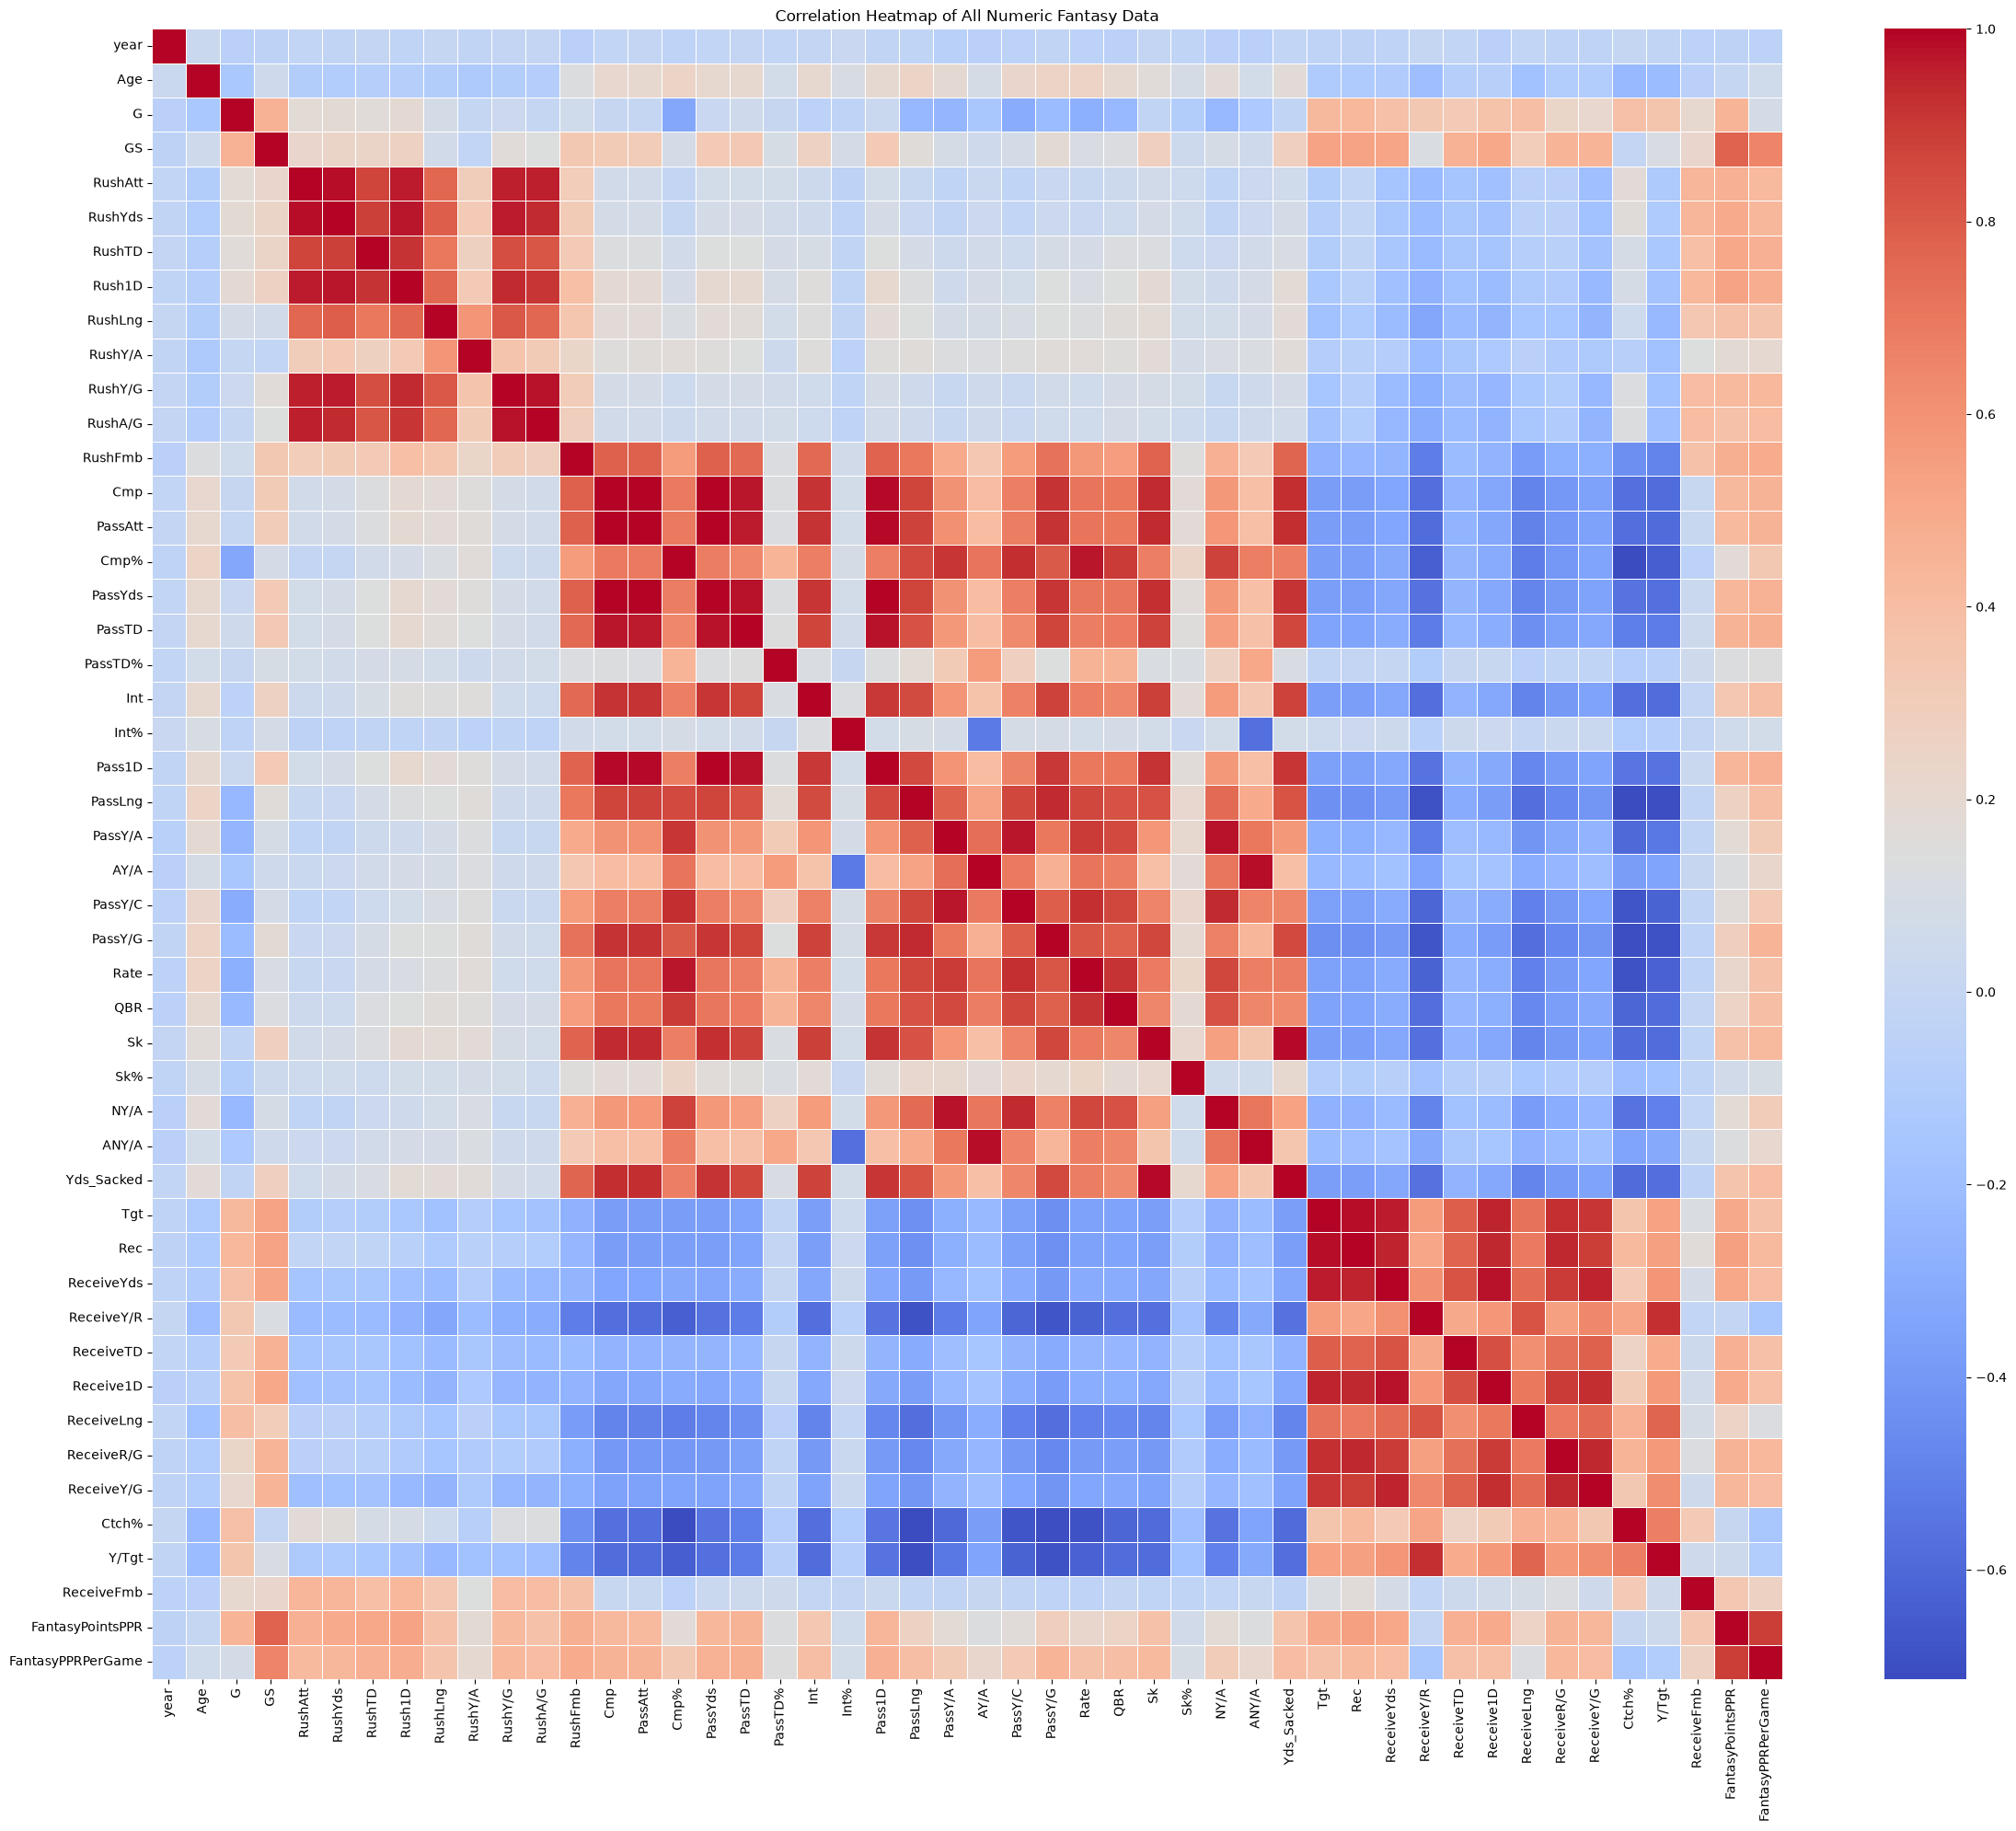

In [72]:
correlation_matrix = df.corr(numeric_only=True)
plt.figure(figsize=(24, 20))
sns.heatmap(correlation_matrix, annot=False, cmap="coolwarm", linewidths=.5)
plt.title("Correlation Heatmap of All Numeric Fantasy Data")
plt.tight_layout()
plt.show()

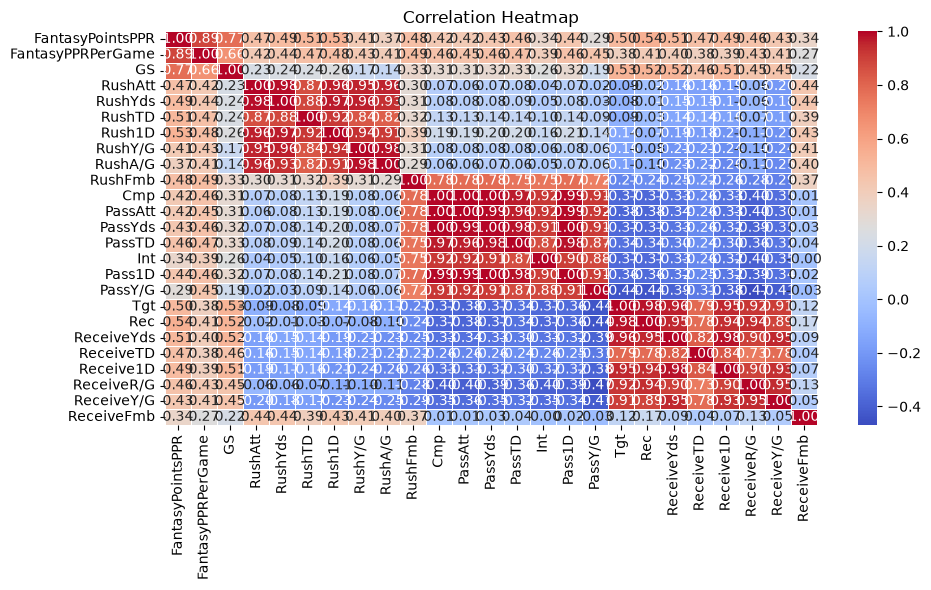

In [73]:
subset = df[['FantasyPointsPPR','FantasyPPRPerGame', 'GS', 'RushAtt', 'RushYds', 'RushTD', 'Rush1D', 'RushY/G', 'RushA/G', 'RushFmb', 'Cmp', 'PassAtt', 'PassYds', 'PassTD', 'Int', 'Pass1D', 'PassY/G', 'Tgt', 'Rec', 'ReceiveYds', 'ReceiveTD', 'Receive1D', 'ReceiveR/G', 'ReceiveY/G', 'ReceiveFmb']]
plt.figure(figsize=(10, 6))
sns.heatmap(subset.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()